# Daily P&L explain: realised vol against implied vol

A desk buys an option, delta-hedges it with futures every evening, and explains its P&L every
evening. This notebook simulates the market day by day, then does the desk's evening work on it.

The question it answers: **when does a delta-hedged long option make money?**

Two vols, two roles:

- **realised vol**: how much the Brent actually moves. It drives the price path.
- **implied vol**: the vol quoted by the market. The desk prices and computes its greeks with it.

1. The simulated market: price and implied vol, day by day
2. Every evening: reprice, greeks, P&L explain, re-hedge
3. The P&L, day after day
4. Three realised vols, same implied vol: who wins?

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import QuantLib as ql

from cmdty import MarketData, Quote
from cmdty.instruments import VanillaOption
from cmdty.models.black76 import analytic_greeks, expected_payoff
from cmdty.plotting import MUTED, SERIES, plot_bars, plot_curves, use_style

use_style()

TODAY = ql.Date(27, 11, 2026)
CALENDAR = ql.UnitedKingdom()  # ICE Brent trades on London business days
F0, IVOL0 = 75.0, 0.32  # future price and implied vol today
U, CONTRACT = "BRENT", "2027-03"
SIZE = 10_000  # bbl per option

## 1. The simulated market

Both paths come from QuantLib processes, simulated together:

| What | Model | QuantLib |
|---|---|---|
| Brent future | geometric Brownian motion, no drift, vol = **realised vol** | `ql.GeometricBrownianMotionProcess` |
| Implied vol | Ornstein-Uhlenbeck: pulled back to its mean (32 %), with noise | `ql.OrnsteinUhlenbeckProcess` |

The two shocks are correlated at −0.3: on oil, implied vol tends to rise when the price falls.
One step = one London business day (1/252 of a year).

In [2]:
def simulate(realised_vol: float, days: int, seed: int, ivol_noise: float = 0.15,
             n_paths: int = 1) -> list[pd.DataFrame]:
    """Business-day paths of the Brent future and its implied vol."""
    price = ql.GeometricBrownianMotionProcess(F0, 0.0, realised_vol)
    # speed 5 per year: a shock to the implied vol halves in about 5 weeks
    ivol = ql.OrnsteinUhlenbeckProcess(5.0, ivol_noise, IVOL0, IVOL0)
    both = ql.StochasticProcessArray([price, ivol], [[1.0, -0.3], [-0.3, 1.0]])
    times = [i / 252 for i in range(days + 1)]
    rng = ql.GaussianRandomSequenceGenerator(
        ql.UniformRandomSequenceGenerator(2 * days, ql.UniformRandomGenerator(seed)))
    paths = ql.GaussianMultiPathGenerator(both, times, rng, False)
    dates = [CALENDAR.advance(TODAY, i, ql.Days) for i in range(days + 1)]
    out = []
    for _ in range(n_paths):
        p = paths.next().value()
        out.append(pd.DataFrame({"date": dates,
                                 "future": [p[0][i] for i in range(days + 1)],
                                 "ivol": [p[1][i] for i in range(days + 1)]}))
    return out


def realised(market: pd.DataFrame) -> float:
    """Annualised vol actually seen on the path: std of daily log returns x sqrt(252)."""
    return float(np.log(market["future"]).diff().std() * np.sqrt(252))


market = simulate(realised_vol=0.32, days=10, seed=7)[0]
market.assign(date=market["date"].map(lambda d: d.ISO())).round(4)

,date,future,ivol
0,2026-11-27,75.0000,0.3200
1,2026-11-30,72.5878,0.3267
2,2026-12-01,73.0911,0.3181
3,2026-12-02,74.6663,0.3305
4,2026-12-03,75.2868,0.3252
5,2026-12-04,77.3006,0.3071
6,2026-12-07,76.8399,0.3031
7,2026-12-08,75.5962,0.2959
8,2026-12-09,73.6181,0.3063
9,2026-12-10,70.9946,0.2993


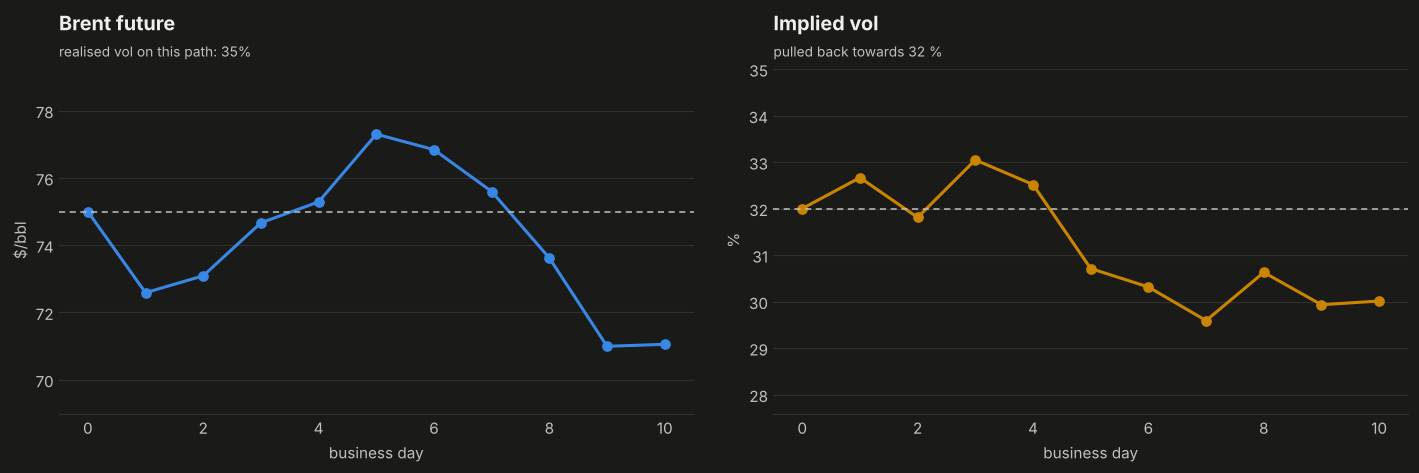

In [3]:
days = range(len(market))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
plot_curves(days, market["future"], ax=axes[0], marker="o", xlabel="business day",
            ylabel="$/bbl", title="Brent future",
            subtitle=f"realised vol on this path: {realised(market):.0%}")
axes[0].axhline(F0, color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
axes[0].set(ylim=(market["future"].min() - 2, market["future"].max() + 2))
plot_curves(days, market["ivol"] * 100, ax=axes[1], marker="o", xlabel="business day",
            ylabel="%", color=SERIES[3], title="Implied vol",
            subtitle="pulled back towards 32 %")
axes[1].axhline(IVOL0 * 100, color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
axes[1].set(ylim=(market["ivol"].min() * 100 - 2, market["ivol"].max() * 100 + 2))
fig.tight_layout(w_pad=2)
plt.show()

Two weeks is short: the vol measured on 10 days is noisy, it can land far from the 32 % used
to draw the path. Part 4 uses longer paths and many of them.

## 2. Every evening: reprice, greeks, P&L explain, re-hedge

The book: a **long straddle at the money**, call 75 + put 75, 10,000 bbl each, 3 months. The
classic vol position: delta about 0, a lot of gamma and vega, theta to pay.

Each evening, with that evening's future price, implied vol and date:

1. **Explain** the day, with yesterday's greeks and today's moves:
   delta × dF + ½ gamma × dF² + vega × dvol + theta (the calendar days elapsed, weekends included).
2. **True P&L**: options repriced tonight, plus the futures held since yesterday.
   Residual = true P&L − the explain.
3. **Re-hedge**: trade futures so that tonight's delta is 0.

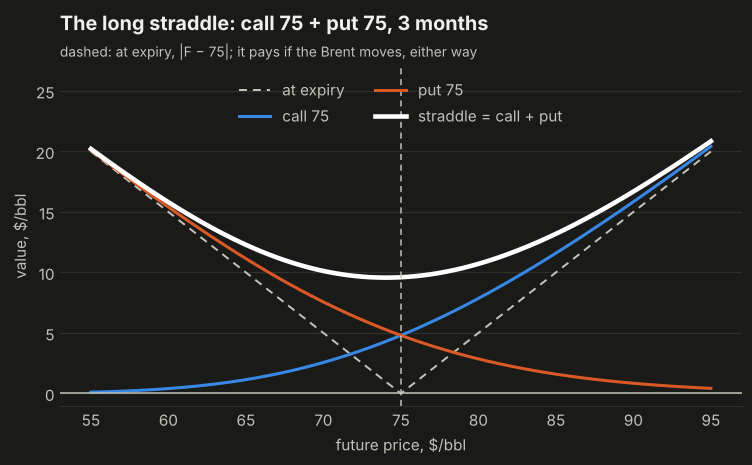

In [4]:
def opt(kind: str, strike: float, qty: float, months: int) -> VanillaOption:
    """One option on the Brent future, qty in bbl (negative = sold)."""
    return VanillaOption(underlying=U, contract=CONTRACT, strike=strike, option_type=kind,
                         quantity=qty, expiry=TODAY + ql.Period(months, ql.Months))


straddle = [opt("call", 75.0, SIZE, 3), opt("put", 75.0, SIZE, 3)]

# the straddle per bbl: value today and at expiry, against the future price
grid = np.linspace(55, 95, 161)
m = lambda f: MarketData(today=TODAY, rate=0.04, quotes={U: Quote(f, IVOL0)})
call = np.array([expected_payoff(straddle[0], m(f)) for f in grid])
put = np.array([expected_payoff(straddle[1], m(f)) for f in grid])
ax = plot_curves(grid, {"call 75": call, "put 75": put, "straddle = call + put": call + put},
            payoff=np.abs(grid - 75.0), f0=F0, ylabel="value, $/bbl",
            title="The long straddle: call 75 + put 75, 3 months",
            subtitle="dashed: at expiry, |F − 75|; it pays if the Brent moves, either way",
            styles={"straddle = call + put": {"color": "white", "linewidth": 3}})
ax.set(ylim=(-1, 27))
ax.legend(frameon=False, loc="upper center", ncol=2)
plt.show()

The straddle is worth the most when the Brent ends far from 75, in either direction, and the
least when it ends right at 75. Today it costs about 9.6 $/bbl (the two premiums): the Brent
has to move more than that by expiry for the straddle to pay back, or the desk has to earn it
by re-hedging the gamma along the way, which is what follows.

In [5]:
def book_value(book, f: float, ivol: float, date: ql.Date) -> float:
    """Value of the options, $ (Black-76, QuantLib, undiscounted)."""
    m = MarketData(today=date, rate=0.04, quotes={U: Quote(f, ivol)})
    return sum(o.quantity * expected_payoff(o, m) for o in book)


def book_greeks(book, f: float, ivol: float, date: ql.Date) -> dict:
    """Delta, gamma, vega ($ per vol point) of the options."""
    m = MarketData(today=date, rate=0.04, quotes={U: Quote(f, ivol)})
    g = [(o.quantity, analytic_greeks(o, m)) for o in book]
    return dict(delta=sum(q * x.delta for q, x in g), gamma=sum(q * x.gamma for q, x in g),
                vega=sum(q * x.vega for q, x in g))


def run_desk(book, market: pd.DataFrame) -> pd.DataFrame:
    """The desk's evening routine on every day of the market path."""
    rows, futures = [], 0.0
    prev = None
    for day in market.itertuples():
        g = book_greeks(book, day.future, day.ivol, day.date)
        value = book_value(book, day.future, day.ivol, day.date)
        row = dict(date=day.date.ISO(), future=day.future, ivol=day.ivol,
                   options_delta=g["delta"], futures_before=futures)
        if prev is not None:
            dF, dvol = day.future - prev.future, (day.ivol - prev.ivol) * 100
            # theta: yesterday's market, tonight's date (weekends included)
            theta = (book_value(book, prev.future, prev.ivol, day.date)
                     - book_value(book, prev.future, prev.ivol, prev.date))
            row |= dict(delta_pnl=(prev_g["delta"] + futures) * dF,
                        gamma_pnl=0.5 * prev_g["gamma"] * dF ** 2,
                        vega_pnl=prev_g["vega"] * dvol, theta_pnl=theta,
                        true_pnl=value - prev_value + futures * dF)
            row["residual"] = row["true_pnl"] - sum(row[k] for k in
                                                    ("delta_pnl", "gamma_pnl", "vega_pnl",
                                                     "theta_pnl"))
        trade = -g["delta"] - futures  # back to delta 0
        futures += trade
        row |= dict(futures_trade=trade, futures_after=futures)
        rows.append(row)
        prev, prev_g, prev_value = day, g, value
    return pd.DataFrame(rows).set_index("date").fillna(0.0)


desk = run_desk(straddle, market)
cols = ["future", "options_delta", "futures_trade", "delta_pnl", "gamma_pnl", "vega_pnl",
        "theta_pnl", "residual", "true_pnl"]
desk[cols].round(0).assign(future=desk["future"].round(2))

,future,options_delta,futures_trade,delta_pnl,gamma_pnl,vega_pnl,theta_pnl,residual,true_pnl
date,,,,,,,,,
2026-11-27,75.00,640.0,-640.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-11-30,72.59,-971.0,1611.0,-0.0,1920.0,1992.0,-1575.0,-22.0,2315.0
2026-12-01,73.09,-693.0,-278.0,0.0,86.0,-2429.0,-522.0,-19.0,-2885.0
2026-12-02,74.67,423.0,-1116.0,0.0,864.0,3531.0,-517.0,48.0,3926.0
2026-12-03,75.29,821.0,-398.0,0.0,127.0,-1539.0,-553.0,-1.0,-1965.0
2026-12-04,77.30,2190.0,-1369.0,0.0,1354.0,-5241.0,-550.0,41.0,-4395.0
2026-12-07,76.84,1901.0,289.0,-0.0,71.0,-1137.0,-1565.0,9.0,-2622.0
2026-12-08,75.60,1007.0,894.0,-0.0,543.0,-2039.0,-523.0,8.0,-2012.0
2026-12-09,73.62,-463.0,1469.0,-0.0,1469.0,2922.0,-516.0,-46.0,3829.0


How to read a row:

- **options_delta**: the straddle's delta tonight. It drifts with the price (gamma).
- **futures_trade**: what the desk trades tonight to bring it back to 0. Price up → delta up →
  sell futures; price down → buy. Sell high, buy low: long gamma.
- **delta_pnl** is 0: the book was hedged the evening before.
- **gamma_pnl** is always ≥ 0 (½ gamma × dF², a square); **theta_pnl** is always < 0, larger
  on Mondays (three calendar days).
- **vega_pnl** follows the implied vol: + when it rises, − when it falls.
- **residual**: what the greeks do not explain, small.

## 3. The P&L, day after day

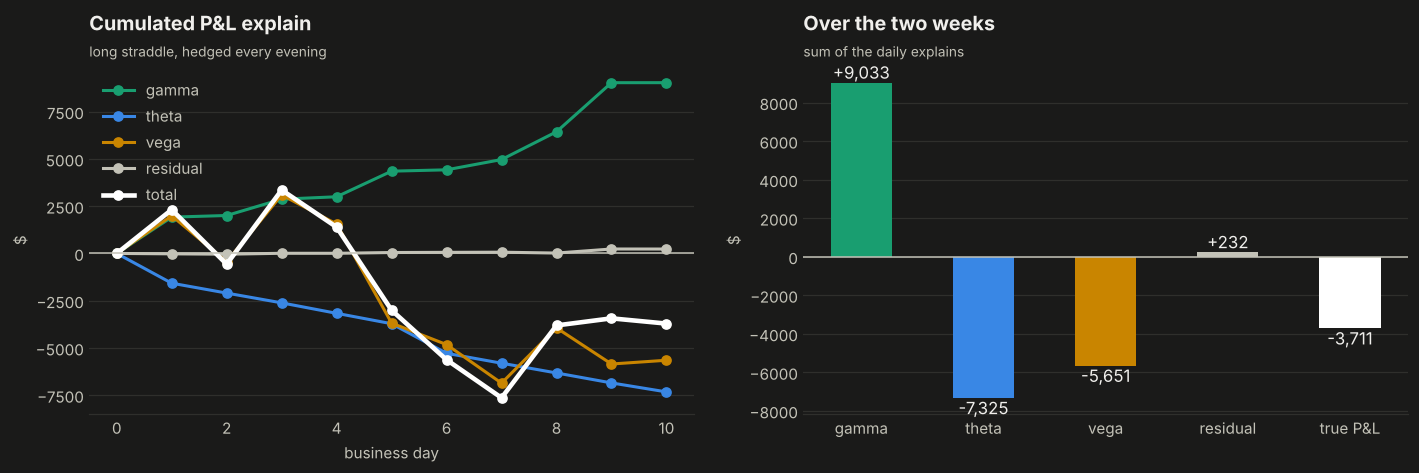

In [6]:
parts = ["gamma_pnl", "theta_pnl", "vega_pnl", "residual"]
cum = desk[parts + ["true_pnl"]].cumsum()
curves = {"gamma": cum["gamma_pnl"], "theta": cum["theta_pnl"], "vega": cum["vega_pnl"],
          "residual": cum["residual"], "total": cum["true_pnl"]}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
plot_curves(days, curves, ax=axes[0], marker="o", xlabel="business day", ylabel="$",
            title="Cumulated P&L explain", subtitle="long straddle, hedged every evening",
            styles={"gamma": {"color": SERIES[2]}, "theta": {"color": SERIES[0]},
                    "vega": {"color": SERIES[3]}, "residual": {"color": MUTED},
                    "total": {"color": "white", "linewidth": 3}})
total = desk[parts + ["true_pnl"]].sum()
plot_bars({"gamma": total["gamma_pnl"], "theta": total["theta_pnl"],
           "vega": total["vega_pnl"], "residual": total["residual"],
           "true P&L": total["true_pnl"]}, ax=axes[1], ylabel="$",
          colors=[SERIES[2], SERIES[0], SERIES[3], MUTED, "white"],
          title="Over the two weeks", subtitle="sum of the daily explains")
fig.tight_layout(w_pad=2)
plt.show()

Gamma (green) climbs on the days the Brent moves a lot, theta (blue) goes down every day like a
staircase. On this path the Brent moved a bit more than the 32 % paid (35 % realised): gamma
(+9.0k) beat theta (−7.3k). But the implied vol fell from 32 % to 30 %, and the vega lost 5.7k:
the total is negative. **Right on the realised vol, wrong on the implied vol**, the two bets
are separate.

## 4. Three realised vols, same implied vol: who wins?

To isolate gamma against theta, the implied vol is now **held at 32 %** (no vega), and only the
realised vol of the price path changes: 20 %, 32 %, 45 %. Three months of business days
(60 days), 100 paths each, the same random numbers for the three.

The rule a vol trader knows by heart: each day, the hedged long option earns about

½ × gamma × F² × (σ²realised − σ²implied) × dt

so it **wins when the realised vol is above the implied vol it paid**, and loses below.

In [7]:
results = {}
for rv in (0.20, 0.32, 0.45):
    paths = simulate(realised_vol=rv, days=60, seed=11, ivol_noise=0.0, n_paths=100)
    results[f"realised {rv:.0%}"] = [run_desk(straddle, p)["true_pnl"].sum() for p in paths]
pnl = pd.DataFrame(results)
pnl.describe().loc[["mean", "std", "min", "max"]].round(0)

,realised 20%,realised 32%,realised 45%
mean,-38591.0,-3618.0,36274.0
std,10497.0,9634.0,19327.0
min,-56327.0,-24588.0,-4068.0
max,-5520.0,21339.0,84331.0


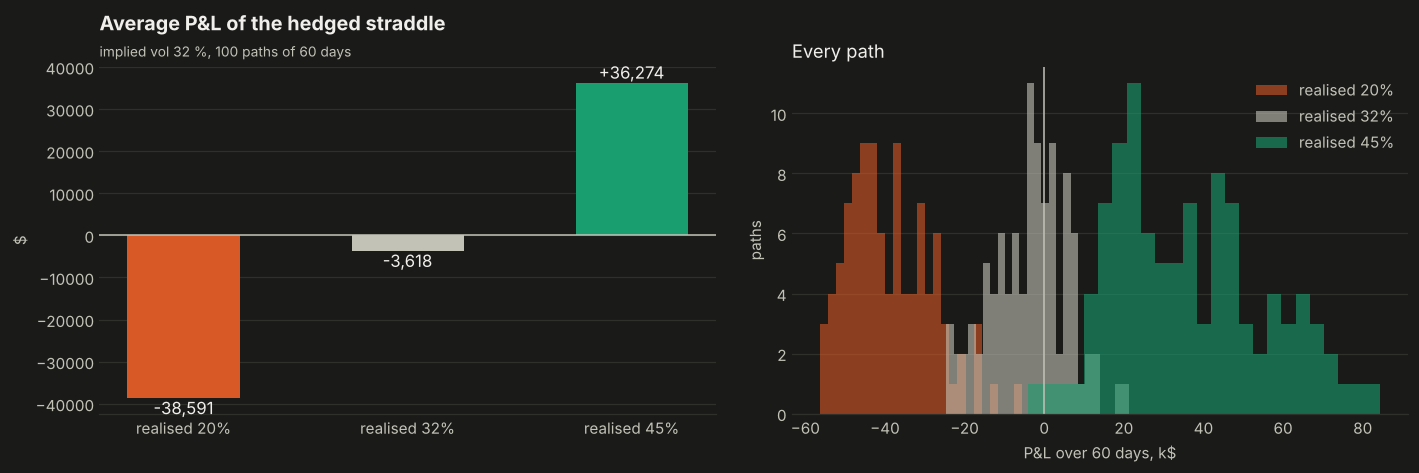

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
plot_bars(pnl.mean().to_dict(), ax=axes[0], colors=[SERIES[1], MUTED, SERIES[2]],
          ylabel="$", title="Average P&L of the hedged straddle",
          subtitle="implied vol 32 %, 100 paths of 60 days")
ax = axes[1]
ax.set_axisbelow(True)
for color, col in zip([SERIES[1], MUTED, SERIES[2]], pnl.columns):
    ax.hist(pnl[col] / 1e3, bins=25, alpha=0.6, color=color, label=col)
ax.axvline(0, color=MUTED, linewidth=1)
ax.set(xlabel="P&L over 60 days, k$", ylabel="paths")
ax.legend(frameon=False)
ax.set_title("Every path", loc="left")
fig.tight_layout(w_pad=2)
plt.show()

- **Realised 20 % < implied 32 %**: the theta paid is not earned back by gamma, the hedged
  straddle loses on average.
- **Realised 32 % = implied**: close to 0 on average (a few k$, against ±38k for the other
  two). Paying the implied vol was a fair price.
- **Realised 45 % > implied**: gamma beats theta, it wins.
- On a single path the result is noisy (the histograms overlap): the price can move a lot on
  days the gamma is low, or the other way round. On average, the rule holds.

A long option hedged in delta is a bet on **realised vol against implied vol**, not on the
direction of the price. Selling the option is the opposite bet: collect theta, hope the market
stays calmer than the implied vol says.

Next step: the vol smile, where each strike has its own implied vol.